# 3D crosshole straight-ray tomography on a TreeMesh

This notebook simulates first-arrival traveltimes in 3D between four boreholes
and an array of surface receivers, then inverts them for **velocity**.

- The mesh is a `discretize.TreeMesh` with fine cells between the boreholes
  and coarse padding outside.
- The model is velocity, connected to the slowness used by the simulation
  through a `ReciprocalMap`. This makes the inverse problem nonlinear, but
  SimPEG handles the derivatives of the map.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import discretize
from simpeg import (
    maps,
    data_misfit,
    regularization,
    optimization,
    inverse_problem,
    inversion,
    directives,
)

from simpeg_seismic import traveltime

## Mesh

The base mesh has 2 m cells over a 128 m cube with its top at $z=0$. We
refine to the finest level in the box spanned by the boreholes and coarsen
away from it.

In [2]:
mesh = discretize.TreeMesh(
    [np.full(64, 2.0)] * 3, origin=[-32.0, -32.0, -128.0], diagonal_balance=True
)
mesh.refine(mesh.max_level - 3, finalize=False)
mesh.refine_box([[-6.0, -6.0, -70.0]], [[66.0, 66.0, 0.0]], [mesh.max_level - 1], finalize=False)
mesh.refine_box([[0.0, 0.0, -64.0]], [[60.0, 60.0, 0.0]], [mesh.max_level], finalize=False)
mesh.finalize()
print(f"{mesh.n_cells:,} cells")

42,463 cells


## True model

The velocity increases with depth, and there is a slow sphere between the
boreholes.

In [3]:
x, y, z = mesh.cell_centers.T
velocity_true = 2000.0 - 10.0 * z
velocity_true[(x - 35) ** 2 + (y - 25) ** 2 + (z + 30) ** 2 < 10**2] *= 0.75

## Survey

There are four boreholes at the corners of a 60 m square, each 60 m deep.

- **Sources:** every 5 m in every borehole.
- **Receivers:** every 2 m in the other three boreholes, plus a 7 x 7 surface
  array.

Rays between boreholes only sample the vertical planes that join them: the
four sides of the square and its two diagonals. The surface receivers fill in
the shallow part of the volume.

In [4]:
def borehole(x, y, spacing):
    depths = np.arange(-58.0, -1.0, spacing)
    return np.c_[np.full_like(depths, x), np.full_like(depths, y), depths]


wells = [(0.0, 0.0), (60.0, 0.0), (60.0, 60.0), (0.0, 60.0)]
gx, gy = np.meshgrid(np.linspace(0, 60, 7), np.linspace(0, 60, 7))
surface = np.c_[gx.ravel(), gy.ravel(), np.zeros(gx.size)]

source_list = []
for i, (xw, yw) in enumerate(wells):
    receiver_locations = np.vstack(
        [borehole(*w, 2.0) for j, w in enumerate(wells) if j != i] + [surface]
    )
    receivers = [traveltime.receivers.Traveltime(receiver_locations)]
    for loc in borehole(xw, yw, 5.0):
        source_list.append(traveltime.sources.PointSource(receiver_list=receivers, location=loc))

survey = traveltime.Survey(source_list)
print(f"{len(source_list)} sources, {survey.nD:,} traveltimes")

48 sources, 6,528 traveltimes


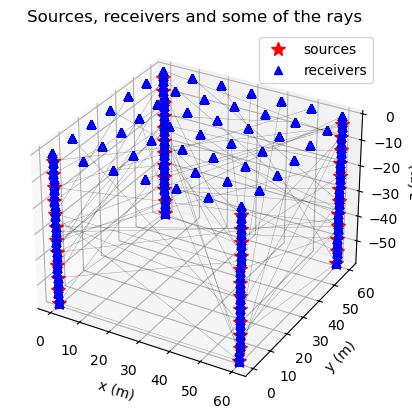

In [5]:
ax = survey.plot(plot_rays=False)
src, rx = survey.ray_endpoints
for i in range(0, survey.nD, 97):  # a subset of the rays, for legibility
    ax.plot(*np.c_[src[i], rx[i]], "k-", lw=0.3, alpha=0.4)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_zlabel("z (m)")
ax.legend()
ax.set_title("Sources, receivers and some of the rays");

## Forward simulation

`slownessMap=maps.ReciprocalMap(mesh)` means the model is velocity and the
simulation converts it to slowness $s = 1/v$.

In [6]:
simulation = traveltime.SimulationStraightRay(
    mesh, survey=survey, slownessMap=maps.ReciprocalMap(mesh)
)

%time G = simulation.G
print(f"G: {G.shape[0]:,} x {G.shape[1]:,}, {G.nnz:,} nonzeros")

data_obs = simulation.make_synthetic_data(
    velocity_true, relative_error=0.0, noise_floor=1e-4, add_noise=True, random_seed=7
)
print(f"traveltimes from {data_obs.dobs.min() * 1e3:.1f} to {data_obs.dobs.max() * 1e3:.1f} ms")

CPU times: user 195 ms, sys: 25.3 ms, total: 220 ms
Wall time: 222 ms
G: 6,528 x 42,463, 372,356 nonzeros
traveltimes from 1.4 to 48.0 ms


Here is a helper that plots an x-z and an x-y slice through the center of the
sphere.

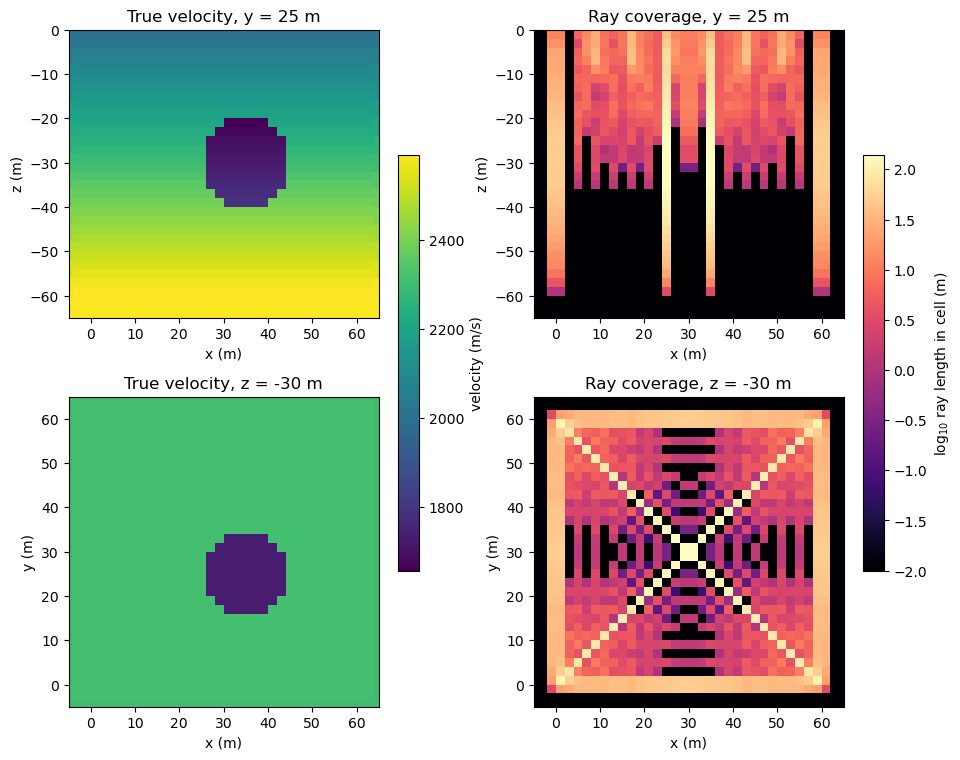

In [7]:
SLICES = [
    ("Y", 25.0, "y = 25 m", ("x (m)", "z (m)"), (-65, 0)),
    ("Z", -30.0, "z = -30 m", ("x (m)", "y (m)"), (-5, 65)),
]


def plot_slices(columns):
    # each column is (model, title, clim, cmap, colorbar label)
    fig, axes = plt.subplots(2, len(columns), figsize=(5.5 * len(columns), 9))
    for j, (model, title, clim, cmap, label) in enumerate(columns):
        for i, (normal, loc, slice_label, (xlabel, ylabel), ylim) in enumerate(SLICES):
            ax = axes[i, j]
            out = mesh.plot_slice(
                model, normal=normal, slice_loc=loc, ax=ax, clim=clim, grid=False,
                pcolor_opts={"cmap": cmap},
            )
            ax.set_xlim(-5, 65)
            ax.set_ylim(*ylim)
            ax.set_aspect("equal")
            ax.set_xlabel(xlabel)
            ax.set_ylabel(ylabel)
            ax.set_title(f"{title}, {slice_label}")
        fig.colorbar(out[0], ax=axes[:, j], label=label, shrink=0.6)
    return axes


coverage = np.asarray(G.sum(axis=0)).ravel()
clim = (velocity_true[coverage > 0].min(), velocity_true[coverage > 0].max())
plot_slices([
    (velocity_true, "True velocity", clim, "viridis", "velocity (m/s)"),
    (np.log10(coverage + 1e-2), "Ray coverage", (-2, None), "magma", "log$_{10}$ ray length in cell (m)"),
]);

## Inversion

The starting and reference model is a homogeneous velocity equal to the
average apparent velocity of the data. We use a smoothness regularization,
cool $\beta$ until $\phi_d \approx N_d$, and bound the velocity between 1000
and 5000 m/s with projected Gauss-Newton.

In [8]:
ray_lengths = np.asarray(G.sum(axis=1)).ravel()
v0 = ray_lengths.sum() / data_obs.dobs.sum()
m0 = np.full(mesh.n_cells, v0)
print(f"starting velocity: {v0:.0f} m/s")

dmis = data_misfit.L2DataMisfit(data=data_obs, simulation=simulation)
reg = regularization.WeightedLeastSquares(
    mesh, reference_model=m0, alpha_s=1e-4, alpha_x=1.0, alpha_y=1.0, alpha_z=1.0
)
opt = optimization.ProjectedGNCG(maxIter=30, lower=1000.0, upper=5000.0, cg_maxiter=30)
inv_prob = inverse_problem.BaseInvProblem(dmis, reg, opt)

directive_list = [
    directives.UpdateSensitivityWeights(every_iteration=False),
    directives.BetaEstimate_ByEig(beta0_ratio=10.0, random_seed=0),
    directives.BetaSchedule(coolingFactor=2.0, coolingRate=1),
    directives.UpdatePreconditioner(),
    directives.TargetMisfit(chifact=1.0),
]
inv = inversion.BaseInversion(inv_prob, directiveList=directive_list)
velocity_rec = inv.run(m0)

/var/folders/sl/j1q3fxbx71q7r5kh4vv1r1rm0000gn/T/ipykernel_28842/2584732802.py:10: FutureWarning: The defaults for ProjectedGNCG will change in SimPEG 0.26.0. If you want to maintain the previous behavior, explicitly set 'cg_atol=1E-3' and 'cg_rtol=0.0'.
  opt = optimization.ProjectedGNCG(maxIter=30, lower=1000.0, upper=5000.0, cg_maxiter=30)
INFO: Directive TargetMisfit: Target data misfit is 6528.0


starting velocity: 2232 m/s

Running inversion with SimPEG v0.25.2
================================================= Projected GNCG =================================================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS   iter_CG   CG |Ax-b|/|b|  CG |Ax-b|   Comment   
-----------------------------------------------------------------------------------------------------------------
   0  3.84e-02  1.91e+06  0.00e+00  1.91e+06                         0           inf          inf                


   1  3.84e-02  6.88e+04  2.94e+06  1.82e+05    2.86e+02      0      30       1.21e-02     3.45e+00              


   2  1.92e-02  3.24e+04  3.81e+06  1.06e+05    3.08e+01      0      30       7.07e-03     2.18e-01              


   3  9.61e-03  2.09e+04  4.63e+06  6.54e+04    1.36e+01      0      30       3.41e-03     4.65e-02              


   4  4.81e-03  1.43e+04  5.57e+06  4.11e+04    9.11e+00      0      30       2.08e-03     1.89e-02              


   5  2.40e-03  1.03e+04  6.74e+06  2.65e+04    6.19e+00      0      30       3.03e-03     1.87e-02              


   6  1.20e-03  7.61e+03  8.28e+06  1.76e+04    4.27e+00      0      30       3.84e-03     1.64e-02              


   7  6.01e-04  5.79e+03  1.04e+07  1.20e+04    2.95e+00      0      30       7.68e-03     2.26e-02              
------------------------- STOP! -------------------------
1 : |fc-fOld| = 5.5211e+02 <= tolF*(1+|f0|) = 1.9063e+05
1 : |xc-x_last| = 1.0307e+03 <= tolX*(1+|x0|) = 4.5994e+04
0 : |proj(x-g)-x|    = 2.9480e+00 <= tolG          = 1.0000e-01
0 : |proj(x-g)-x|    = 2.9480e+00 <= 1e3*eps       = 1.0000e-02
0 : maxIter   =      30    <= iter          =      7
------------------------- DONE! -------------------------


## Results

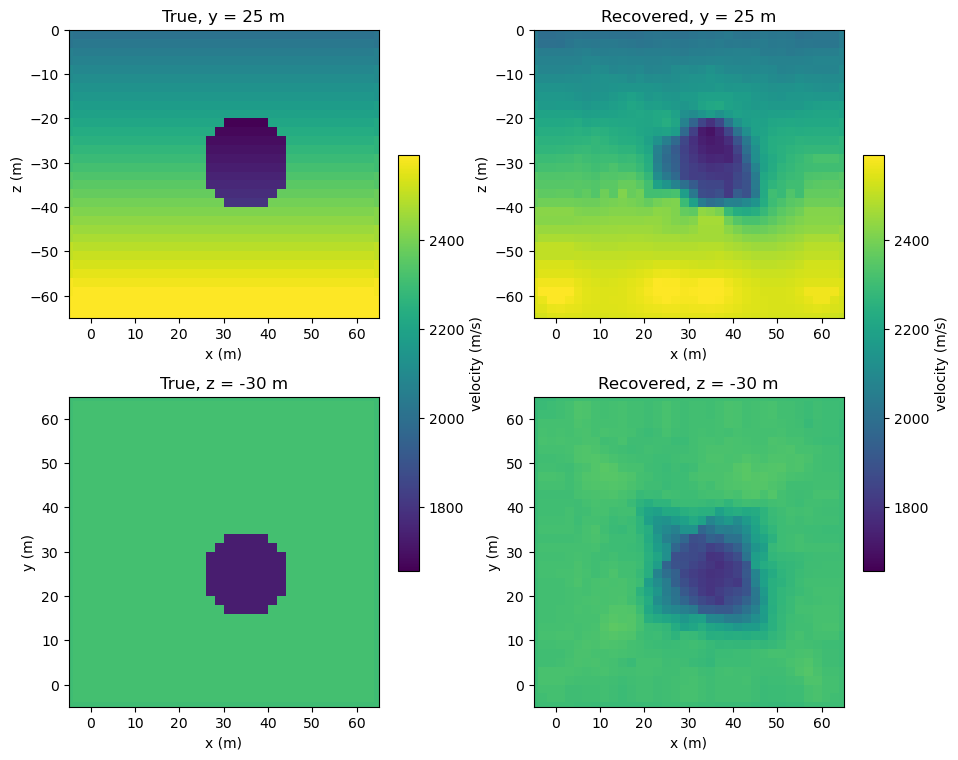

In [9]:
plot_slices([
    (velocity_true, "True", clim, "viridis", "velocity (m/s)"),
    (velocity_rec, "Recovered", clim, "viridis", "velocity (m/s)"),
]);

The sphere is recovered in the right place, but it is smoothed and its
contrast is reduced, as expected for a smooth inversion of traveltimes. The
depth gradient is recovered in the planes between the boreholes, where there
are rays. Between those planes, the model is filled in by the smoothness
regularization.

To finish, here is the data fit.

phi_d = 5,786 for 6,528 data


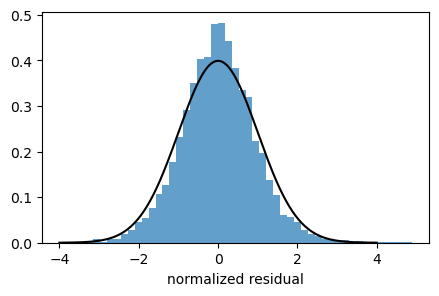

In [10]:
residual = (simulation.dpred(velocity_rec) - data_obs.dobs) / data_obs.standard_deviation
print(f"phi_d = {np.sum(residual**2):,.0f} for {survey.nD:,} data")

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(residual, bins=50, density=True, alpha=0.7)
xx = np.linspace(-4, 4, 200)
ax.plot(xx, np.exp(-(xx**2) / 2) / np.sqrt(2 * np.pi), "k")
ax.set_xlabel("normalized residual");